### Финальный проект по датасету Titanic

In [1]:
# переход в корень проекта,
# чтобы работали импорты из src и пути из config.yaml.
%cd ..

/Users/anhedonia/Desktop/Titanic


In [2]:
import yaml 
import matplotlib.pyplot as plt

plt.style.use("dark_background")

from src.data import load_data

In [3]:
with open("config.yaml") as file:
    config = yaml.safe_load(file)

train_path = config["data"]["training_path"]
test_path = config["data"]["test_path"]
train_data, test_data = load_data(train_path, test_path)

In [4]:
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


### Выводы:
- `Age`: пропущено 177 из 891(19,87 %) - возьмем медиану.
- `Cabin`:  пропущено 687 из 891 (77,1 %) - заменим признак на известно/неизвестно.
- `Embarked`: пропущено 2 из 891 (0,22 %) -возьмем самое частое значение.
- Числовые столбцы: `PassengerId`, `Survived`, `Pclass`, `Age`, `Parch`, `Fare`, `SibSp`.
- Текстовые столбцы: `Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`.
- Столбцы, которые по смыслу категория, но хранятся как числа: `Survived`, `Pclass`.
- В признаке `Name` имеются категории пассажиров: Mr, Mrs, Miss, Master. По этим титулам можно сделать новый признак. Значения этих титулов могут помочь точнее заполнить пропуски в `Age`.

## 2. Целевая переменная.
 Считаем проценты выживших и погибших

In [6]:
train_data["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [7]:
train_data["Survived"].value_counts(normalize=True)

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

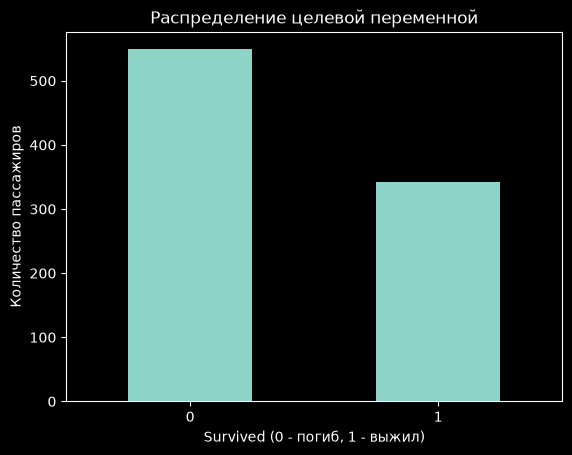

In [8]:
train_data["Survived"].value_counts().plot(kind="bar", rot=0)
plt.title("Распределение целевой переменной")
plt.xlabel("Survived (0 - погиб, 1 - выжил)")
plt.ylabel("Количество пассажиров")
plt.show()


### Вывод:
- Погибло 549 человек (62%).
- Выжило 342 человека (38%).
- Умеренный дисбаланс 62/38.
- Умеренный дисбаланс значит, что при CV нужно сохранять эту пропорцию в каждом фолде.
- Если модель будет всегда отвечать - погиб, то точность составит 62% - это нижняя планка, все модели должны ее превзойти.


### 3. Распределение числовых признаков
Где больше всего значений,
Есть ли выбросы,
Есть ли скошенность.


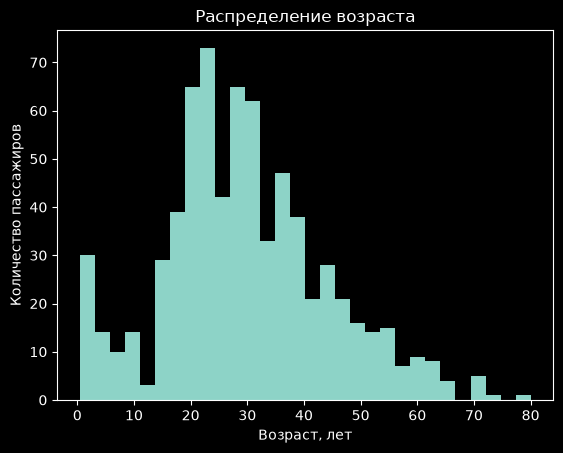

In [9]:
train_data["Age"].plot(kind="hist", bins=30)
plt.title("Распределение возраста")
plt.xlabel("Возраст, лет")
plt.ylabel("Количество пассажиров")
plt.show()

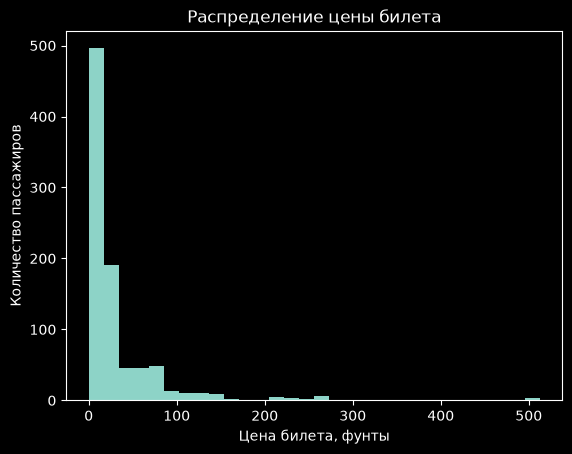

In [10]:
train_data["Fare"].plot(kind="hist", bins=30)
plt.title("Распределение цены билета")
plt.xlabel("Цена билета, фунты")
plt.ylabel("Количество пассажиров")
plt.show()

### Выводы:
**Age**
- большинство людей в возрасте от 20 до 40 лет, пик 20-30.
- распределение слегка скошено вправо, выбросы отсутствуют.
- cреди детей больше всего малышей от 0 до 4 лет(около 30).
- гипотеза: дети выживали чаще взрослых - проверить в разделе 4.

**Fare**
- большинство билетов дешевле 40 фунтов
- распределение сильно скошено вправо
- выбросы: несколько билетов около 500 фунтов
- следствие: для линейных моделей, KNN и нейросети понадобится логарифмирование

### 4. Связь признаков с выживаемостью
Проверим гипотезы: выживали ли женщины чаще, выживали ли дети чаще взрослых, влиял ли класс билета

In [11]:
train_data.groupby("Sex")["Survived"].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [12]:
train_data.groupby("Pclass")["Survived"].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [13]:
train_data[train_data["Age"] < 5]["Survived"].mean()

np.float64(0.675)

In [14]:
train_data[train_data["Age"] >= 18]["Survived"].mean()

np.float64(0.3810316139767055)

In [15]:
len(train_data[train_data["Age"] < 5])

40

### Выводы: 
**Sex**
- выжило 74% женищин и 19% мужчин, почти в 4 раза больше
- следствие: гипотеза о более высокой выживаемости женщин подтверлилась

**Pclass**
- выживаемость падает с 1 класса к 3: 63% - 47% - 24%
- следствие: гипотеза о выживемости более высокго класса пассажиров подтвердилась

**Возраст: дети и взрослые**
- среди детей до 5 лет выжило 68% (40 человек) доля взрослых 38%
- следствие: гипотеза из раздела 3 подтвердилась
